# Lab: generate handwritten digits with NCSN

**Data:** MNIST · **Images:** 28 × 28 grayscale · **U-Net channels:** 32 / 64 / 128 · **Attention:** none

Learn the scores of ten Gaussian-perturbed data distributions, then generate digits using
annealed Langevin dynamics. This notebook follows the attached DDPM lab's sequence: setup,
data, noise schedule, U-Net, objective, training, learning curves, and generation with trajectories.
Digit labels are never supplied to the model.

**What is retained:** the attachment's residual U-Net layers, GroupNorm, skip connections,
sinusoidal embedding, and learned embedding projections. **What changes:** additive Gaussian
corruption, ten noise levels, the weighted denoising score-matching loss, and the sampler.
This uses NCSN's objective and sampling algorithm with the requested DDPM-style U-Net;
it does not reproduce the original paper's RefineNet architecture or benchmark results.

| Setting | Default |
|:--|:--|
| Clean-image pixel scale | $[0,1]$, with the original code's uniform dequantization |
| Noise schedule | $L=10$ geometric standard deviations, $0.01=\sigma_1<\cdots<\sigma_{10}=1$ |
| Training | One uniformly sampled level per image; $\lambda(\sigma)=\sigma^2$ |
| Optimizer | Adam, learning rate $2\times10^{-4}$, batch size 128; same as the DDPM lab |
| Sampling | Uniform initialization; largest to smallest noise; $K=100$ updates at each level |
| Langevin step | $\alpha_i=2\times10^{-5}(\sigma_i/0.01)^2$, drift $\alpha_i s_\theta/2$ |
| Total sampling work | $10\times100=1000$ U-Net evaluations per trajectory |

**Run guide.** Run cells from top to bottom in Jupyter or Colab. A GPU is recommended.
Set **`EPOCHS=30`** for the full run, matching the attached DDPM lab. `QUICK_RUN=True`
uses two epochs on a small subset; it still uses all ten levels and all 1,000 sampling updates.
Batch size, Adam learning rate, EMA decay, and gradient clipping also match the DDPM lab.
Short training is not a test of final sample quality. Internet is needed for the first MNIST
download and any missing packages.

The notebook is ready to run and contains no pretrained weights or completed full-training run.
It saves checkpoints, metrics, figures, raw trajectories, and an optional GIF in a new output directory.

Source: [Song and Ermon (2019), Sections 4–5](https://papers.nips.cc/paper/2019/file/3001ef257407d5a371a96dcd947c7d93-Paper.pdf)
and the [authors' NCSN code](https://github.com/ermongroup/ncsn).


## 1. Setup and experiment settings

Install only missing packages, leaving an existing PyTorch installation unchanged.
PyTorch and torchvision must be a compatible pair; Colab normally supplies both.


In [1]:
import importlib.util
import subprocess
import sys

requirements = {
    'torch': 'torch', 'torchvision': 'torchvision', 'numpy': 'numpy',
    'pandas': 'pandas', 'matplotlib': 'matplotlib', 'tqdm': 'tqdm', 'PIL': 'pillow',
}
missing = [package for module, package in requirements.items()
           if importlib.util.find_spec(module) is None]
if missing:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', *missing])
else:
    print('All required packages are available.')


All required packages are available.


In [2]:
import copy
import json
import math
import os
import random
import time
from datetime import datetime
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from IPython.display import display, Image as DisplayImage
from tqdm.auto import tqdm

import torch
import torch.nn.functional as F
from torch import nn
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms
from torchvision.utils import make_grid, save_image


def seed_everything(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


if torch.cuda.is_available():
    device = torch.device('cuda')
elif hasattr(torch.backends, 'mps') and torch.backends.mps.is_available():
    device = torch.device('mps')
else:
    device = torch.device('cpu')
    torch.set_num_threads(min(4, os.cpu_count() or 1))

plt.rcParams.update({'figure.dpi': 110, 'font.size': 10,
                     'axes.spines.top': False, 'axes.spines.right': False})
print('PyTorch:', torch.__version__, '| device:', device)


PyTorch: 2.7.0 | device: mps


Set `EPOCHS` to the number of complete passes through the training data. The default is
**30 epochs**, or **2 epochs** in quick mode, matching the attached DDPM notebook.
The shared training settings also match: batch size 128, Adam learning rate `2e-4`,
EMA enabled with decay `0.999`, and gradient clipping at `1.0`.

The NCSN noise schedule, weighted DSM loss, embedding mapping, and annealed Langevin sampler
are unchanged. `LEARNING_RATE` controls training; `BASE_ALPHA` controls sampling.
`BASE_CHANNELS=16` reduces model size if needed.

`LOAD_CHECKPOINT` loads a matching notebook checkpoint and skips training; it does not resume
the optimizer. Leave it as `None` for a new run. EMA weights are used by default for validation
and generation, as in the attached DDPM lab; set `USE_EMA=False` to use raw weights instead.


In [3]:
SEED = 42
QUICK_RUN = False
IMAGE_SIZE = 28
BASE_CHANNELS = 32
TIME_DIM = 128
DROPOUT = 0.0

L = 10
SIGMA_MIN, SIGMA_MAX = 0.01, 1.0       # Standard deviations, not variances.
EMBEDDING_MAX = 1000.0                # Ten coordinates spread over [1, 1000].
K = 100                              # Langevin updates PER noise level.
BASE_ALPHA = 2e-5                     # Paper convention: drift alpha/2, noise sqrt(alpha).
# Set BASE_ALPHA=4e-5 to match the released code's h=2e-5 convention; see Section 8.

BATCH_SIZE = 128
LEARNING_RATE = 2e-4                  # Same as the DDPM lab; unrelated to BASE_ALPHA.
EPOCHS = 2 if QUICK_RUN else 30
DEQUANTIZE = True                     # x <- (255*x + U[0,1))/256, as in released code.
USE_EMA = True                        # Same EMA default as the DDPM lab.
EMA_DECAY = 0.999
GRAD_CLIP = 1.0                       # Same gradient clipping as the DDPM lab.

VAL_SIZE = 5_000
TRAIN_LIMIT = 2_048 if QUICK_RUN else None
EVAL_LIMIT = 256 if QUICK_RUN else None
NUM_WORKERS = 0
SHOW_PROGRESS = True
DATA_ROOT = Path('./data')
DOWNLOAD = True
LOAD_CHECKPOINT = None                # Example: Path('outputs/.../best_ncsn.pt')

NUM_GENERATED = 8
SAMPLE_SEED = 2026
SAVE_GIF = True
SNAPSHOT_EVERY = 10                   # Records frames; does NOT skip Langevin updates.
OUTPUT_ROOT = Path('./outputs')
RUN_DIR = OUTPUT_ROOT / f'mnist_ncsn_{datetime.now():%Y%m%d_%H%M%S_%f}'
RUN_DIR.mkdir(parents=True, exist_ok=False)

assert IMAGE_SIZE == 28 and BASE_CHANNELS >= 8 and BASE_CHANNELS % 8 == 0
assert TIME_DIM >= 4 and isinstance(EPOCHS, int) and EPOCHS >= 1 and BATCH_SIZE >= 1
assert L >= 2 and 0 < SIGMA_MIN < SIGMA_MAX and EMBEDDING_MAX > 1
assert K >= 1 and BASE_ALPHA > 0 and SNAPSHOT_EVERY >= 1
assert 0 <= DROPOUT < 1 and 0 <= EMA_DECAY < 1
seed_everything(SEED)
print(f'Channels: {BASE_CHANNELS}, {2*BASE_CHANNELS}, {4*BASE_CHANNELS}; no attention')
print(f'Training: {EPOCHS} epochs | batch size: {BATCH_SIZE} | EMA: {USE_EMA}')
print(f'Sampling: {L} levels × {K} updates = {L*K} U-Net evaluations | quick: {QUICK_RUN}')
print('Outputs:', RUN_DIR.resolve())


Channels: 32, 64, 128; no attention
Training: 30 epochs | batch size: 128 | EMA: True
Sampling: 10 levels × 100 updates = 1000 U-Net evaluations | quick: False
Outputs: /Users/xig16121/Desktop/Teaching/Special/code/pytorch/outputs/mnist_ncsn_20261026_195226_820086


## 2. Load MNIST

Keep the attachment's fixed split: 55,000 training images, 5,000 validation images, and the
separate official test set. Quick mode subsets these splits. Images remain 28 × 28, with no
digit flips, resizing, or binarization.

**Use `ToTensor()` only:** pixels stay in $[0,1]$, the scale used for the paper's noise schedule.
During training/evaluation, optional uniform dequantization replaces $x$ by
$(255x+u)/256$, with independent $u\sim\mathrm{Unif}[0,1)$ per pixel. This follows the released
NCSN code. The Gaussian corruption is added afterward and is **not clipped**.


In [4]:
transform = transforms.ToTensor()
mnist_train = datasets.MNIST(DATA_ROOT, train=True, download=DOWNLOAD, transform=transform)
mnist_test = datasets.MNIST(DATA_ROOT, train=False, download=DOWNLOAD, transform=transform)

permutation = torch.randperm(len(mnist_train), generator=torch.Generator().manual_seed(SEED))
val_indices = permutation[:VAL_SIZE].tolist()
train_indices = permutation[VAL_SIZE:].tolist()
if TRAIN_LIMIT is not None:
    train_indices = train_indices[:TRAIN_LIMIT]
if EVAL_LIMIT is not None:
    val_indices = val_indices[:EVAL_LIMIT]

train_data = Subset(mnist_train, train_indices)
val_data = Subset(mnist_train, val_indices)
test_data = (Subset(mnist_test, range(min(EVAL_LIMIT, len(mnist_test))))
             if EVAL_LIMIT is not None else mnist_test)

loader_options = dict(batch_size=BATCH_SIZE, num_workers=NUM_WORKERS,
                      pin_memory=(device.type == 'cuda'))
train_loader = DataLoader(train_data, shuffle=True,
                          generator=torch.Generator().manual_seed(SEED), **loader_options)
val_loader = DataLoader(val_data, shuffle=False, **loader_options)
test_loader = DataLoader(test_data, shuffle=False, **loader_options)
print(f'Train: {len(train_data):,}; validation: {len(val_data):,}; test: {len(test_data):,}')


Train: 55,000; validation: 5,000; test: 10,000


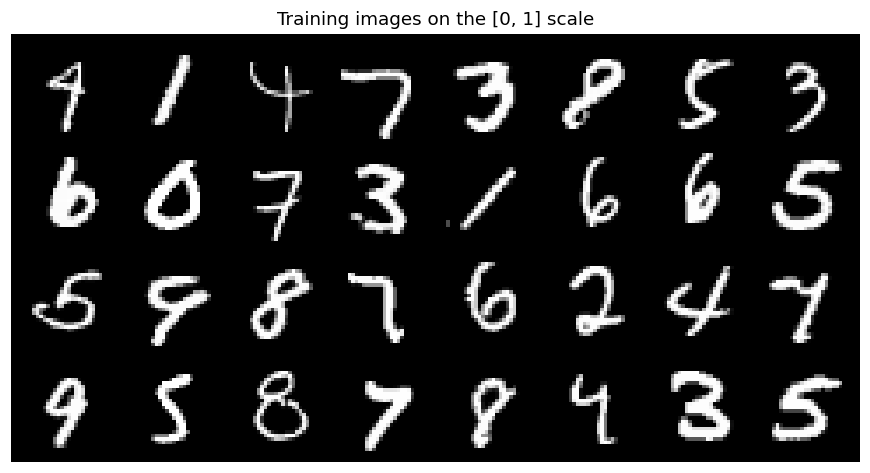

In [5]:
def to_display(images):
    # A fixed intensity scale for every image. This never modifies the sampler's tensors.
    return images.detach().cpu().clamp(0, 1)


def show_digits(images, title, nrow=8, filename=None):
    grid = make_grid(to_display(images), nrow=nrow, padding=2, pad_value=0)
    fig, ax = plt.subplots(figsize=(min(10, nrow * 1.1), max(2, math.ceil(len(images)/nrow)*1.1)))
    ax.imshow(grid.permute(1, 2, 0).numpy(), vmin=0, vmax=1)
    ax.set(title=title)
    ax.axis('off')
    fig.tight_layout()
    if filename is not None:
        fig.savefig(filename, dpi=160, bbox_inches='tight')
    plt.show()
    plt.close(fig)


def show_trajectories(states, labels, title, prefix=None, rows_per_figure=8):
    """states: (number of saved times, number of images, 1, H, W). Every image gets a row."""
    assert states.ndim == 5 and len(states) == len(labels)
    images = to_display(states)
    n_images = states.shape[1]
    for start in range(0, n_images, rows_per_figure):
        end = min(start + rows_per_figure, n_images)
        fig, axes = plt.subplots(end-start, len(labels), squeeze=False,
                                 figsize=(1.15*len(labels), 1.15*(end-start)+0.65))
        for row, sample_id in enumerate(range(start, end)):
            for col, label in enumerate(labels):
                ax = axes[row, col]
                ax.imshow(images[col, sample_id, 0], cmap='gray', vmin=0, vmax=1)
                ax.set_xticks([]); ax.set_yticks([])
                for spine in ax.spines.values():
                    spine.set_visible(False)
                if row == 0:
                    ax.set_title(label)
                if col == 0:
                    ax.set_ylabel(f'Image {sample_id+1}')
        fig.suptitle(title, y=1.01)
        fig.tight_layout()
        if prefix is not None:
            fig.savefig(f'{prefix}_{start+1:02d}-{end:02d}.png', dpi=160, bbox_inches='tight')
        plt.show()
        plt.close(fig)


show_digits(torch.stack([train_data[i][0] for i in range(32)]),
            'Training images on the [0, 1] scale',
            filename=RUN_DIR / 'training_examples.png')


## 3. Gaussian perturbation and the geometric noise schedule

We follow our lecture's **increasing** indexing (the original paper lists the same levels in reverse):
$$
\sigma_i=\sigma_{\min}\left(\frac{\sigma_{\max}}{\sigma_{\min}}\right)^{(i-1)/(L-1)},
\qquad i=1,\ldots,L.
$$
In Python, `level=0` means $\sigma_1=0.01$ and `level=9` means $\sigma_{10}=1$.
There is no zero-noise training level. At a sampled level,
$$
\tilde x_i=x+\sigma_i\epsilon,\qquad \epsilon\sim\mathcal N(0,I_{784}).
$$
Training draws this marginal directly; no forward Markov chain or Langevin simulation is needed.

**Conditioning ten levels with the attached sinusoidal encoding.** Before calling the unchanged
U-Net, map the level to a floating-point embedding coordinate
$$
\tau_i=1+999\frac{i-1}{L-1}
=1+999\frac{\log\sigma_i-\log\sigma_{\min}}
                 {\log\sigma_{\max}-\log\sigma_{\min}}.
$$
The ten coordinates span the original lab's $[1,1000]$ range. This spreads their sinusoidal phases
without creating additional noise levels. Directly encoding indices 0–9 is also possible;
this rescaling is a design choice for reusing the attachment, not a requirement of NCSN.
Original NCSN used learned conditional-normalization tables instead.


In [6]:
class NoiseSchedule(nn.Module):
    def __init__(self, levels=10, sigma_min=0.01, sigma_max=1.0, embedding_max=1000.0):
        super().__init__()
        if levels < 2 or not 0 < sigma_min < sigma_max or embedding_max <= 1:
            raise ValueError('Need at least two positive increasing noise levels and embedding_max > 1.')
        self.levels = int(levels)
        self.embedding_max = float(embedding_max)
        sigmas = torch.exp(torch.linspace(math.log(sigma_min), math.log(sigma_max),
                                         self.levels, dtype=torch.float64)).float()
        coordinates = torch.linspace(1.0, embedding_max, self.levels, dtype=torch.float64).float()
        self.register_buffer('sigmas', sigmas)             # Ascending; no dummy zero entry.
        self.register_buffer('embedding_coordinates', coordinates)

    def extract_sigma(self, level):
        return self.sigmas[level].view(-1, 1, 1, 1)

    def embedding_time(self, level):
        return self.embedding_coordinates[level]          # Float; do not round to integers.

    def q_sample(self, x, level, epsilon=None):
        if epsilon is None:
            epsilon = torch.randn_like(x)
        return x + self.extract_sigma(level) * epsilon

    def sampling_alphas(self, base_alpha=2e-5):
        return base_alpha * (self.sigmas / self.sigmas[0]).square()


schedule = NoiseSchedule(L, SIGMA_MIN, SIGMA_MAX, EMBEDDING_MAX).to(device)
schedule_table = pd.DataFrame({
    'math_level_i': range(1, L+1), 'python_level': range(L),
    'sigma': schedule.sigmas.cpu().numpy(),
    'sigma_squared': schedule.sigmas.square().cpu().numpy(),
    'embedding_coordinate': schedule.embedding_coordinates.cpu().numpy(),
    'sampling_alpha': schedule.sampling_alphas(BASE_ALPHA).cpu().numpy(),
})
display(schedule_table)
schedule_table.to_csv(RUN_DIR / 'noise_schedule.csv', index=False)
print('Sampling reads this table from bottom to top.')


,math_level_i,python_level,sigma,sigma_squared,embedding_coordinate,sampling_alpha
0,1,0,0.010000,0.000100,1.0,0.000020
1,2,1,0.016681,0.000278,112.0,0.000056
2,3,2,0.027826,0.000774,223.0,0.000155
3,4,3,0.046416,0.002154,334.0,0.000431
4,5,4,0.077426,0.005995,445.0,0.001199
5,6,5,0.129155,0.016681,556.0,0.003336
6,7,6,0.215443,0.046416,667.0,0.009283
7,8,7,0.359381,0.129155,778.0,0.025831
8,9,8,0.599484,0.359381,889.0,0.071876
9,10,9,1.000000,1.000000,1000.0,0.200000


Sampling reads this table from bottom to top.


Use the **same Gaussian draw** across levels in the next figure to make the progression visible.
These are coupled marginal examples, not a simulated forward Markov chain. Display values are
clipped to $[0,1]$ on a fixed intensity scale; the actual noisy tensors remain unrestricted.


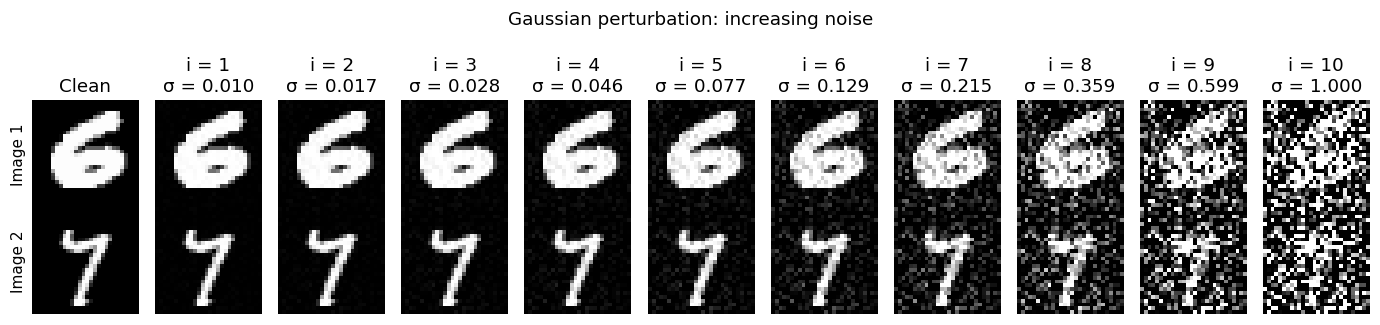

In [7]:
x_examples = torch.stack([val_data[i][0] for i in range(2)]).to(device)
epsilon = torch.randn(x_examples.shape, generator=torch.Generator().manual_seed(SEED+1)).to(device)
with torch.inference_mode():
    forward_states = torch.stack([x_examples.cpu()] + [
        schedule.q_sample(x_examples, torch.full((2,), level, device=device, dtype=torch.long),
                          epsilon).cpu()
        for level in range(schedule.levels)
    ])
forward_labels = ['Clean'] + [f'i = {i+1}\nσ = {s:.3f}'
                              for i, s in enumerate(schedule.sigmas.cpu().tolist())]
show_trajectories(forward_states, forward_labels, 'Gaussian perturbation: increasing noise',
                  prefix=RUN_DIR / 'forward')


## 4. A small, attention-free residual U-Net

The model implements $\epsilon_\theta(\tilde x_i,i)$ and returns a tensor with the **same shape as the
input image**. The output is an unrestricted real-valued noise prediction, so there is no
sigmoid or tanh output activation.

| Stage | Feature shape, excluding batch | Operations |
|:--|:--|:--|
| Input stem | 32 × 28 × 28 | 3 × 3 convolution |
| Encoder level 1 | 32 × 28 × 28 | 2 residual blocks; save skip |
| Downsample | 64 × 14 × 14 | Stride-2 convolution |
| Encoder level 2 | 64 × 14 × 14 | 2 residual blocks; save skip |
| Downsample | 128 × 7 × 7 | Stride-2 convolution |
| Bottleneck | 128 × 7 × 7 | 2 residual blocks |
| Decoder level 2 | 64 × 14 × 14 | Upsample, concatenate 64-channel skip, 2 residual blocks |
| Decoder level 1 | 32 × 28 × 28 | Upsample, concatenate 32-channel skip, 2 residual blocks |
| Output | 1 × 28 × 28 | GroupNorm, SiLU, 3 × 3 convolution |

The table uses `BASE_CHANNELS=32`; all widths scale with that setting. Downsampling uses
3 × 3 stride-2 convolutions with padding 1. Upsampling uses nearest-neighbor resizing followed by a
3 × 3 convolution. Skip connections **concatenate channels**, while the short connection
inside each residual block **adds** its input (projected by 1 × 1 convolution when needed).

**Noise conditioning.** A fixed sinusoidal encoding of $\tau_i$ passes through a learned MLP. Each
residual block projects the resulting vector to its output channel count and adds it to the
feature map. This gives one shared network information about the current noise level.


The two code cells below are unchanged from the attached notebook. A small wrapper converts a
noise-level index to $\tau_i$ and interprets the output as
$s_\theta(\tilde x_i,\sigma_i)=-\epsilon_\theta(\tilde x_i,i)/\sigma_i$.
Each residual block has its own learned projection of the shared embedding; the embedding is
added once inside each block, between its two convolutions.


In [8]:
def group_norm(channels):
    groups = next(g for g in (8, 4, 2, 1) if channels % g == 0)
    return nn.GroupNorm(groups, channels)


class SinusoidalTimeEmbedding(nn.Module):
    def __init__(self, dim):
        super().__init__()
        assert dim >= 4 and dim % 2 == 0
        half = dim // 2
        frequencies = torch.exp(-math.log(10000) * torch.arange(half) / (half - 1))
        self.register_buffer('frequencies', frequencies)

    def forward(self, t):
        angles = t.float()[:, None] * self.frequencies[None, :]
        return torch.cat([angles.sin(), angles.cos()], dim=-1)


class ResidualBlock(nn.Module):
    def __init__(self, in_channels, out_channels, time_dim, dropout=0.0):
        super().__init__()
        self.norm1 = group_norm(in_channels)
        self.conv1 = nn.Conv2d(in_channels, out_channels, 3, padding=1)
        self.time_projection = nn.Linear(time_dim, out_channels)
        self.norm2 = group_norm(out_channels)
        self.dropout = nn.Dropout(dropout)
        self.conv2 = nn.Conv2d(out_channels, out_channels, 3, padding=1)
        self.skip = (nn.Identity() if in_channels == out_channels
                     else nn.Conv2d(in_channels, out_channels, 1))

    def forward(self, x, time_embedding):
        h = self.conv1(F.silu(self.norm1(x)))
        h = h + self.time_projection(F.silu(time_embedding))[:, :, None, None]
        h = self.conv2(self.dropout(F.silu(self.norm2(h))))
        return h + self.skip(x)


In [9]:
class SmallUNet(nn.Module):
    def __init__(self, base_channels=32, time_dim=128, dropout=0.0):
        super().__init__()
        c = base_channels
        self.time_mlp = nn.Sequential(
            SinusoidalTimeEmbedding(c), nn.Linear(c, time_dim), nn.SiLU(),
            nn.Linear(time_dim, time_dim),
        )
        self.stem = nn.Conv2d(1, c, 3, padding=1)
        self.enc28 = nn.ModuleList([ResidualBlock(c, c, time_dim, dropout) for _ in range(2)])
        self.down28 = nn.Conv2d(c, 2*c, 3, stride=2, padding=1)
        self.enc14 = nn.ModuleList([ResidualBlock(2*c, 2*c, time_dim, dropout) for _ in range(2)])
        self.down14 = nn.Conv2d(2*c, 4*c, 3, stride=2, padding=1)
        self.middle = nn.ModuleList([ResidualBlock(4*c, 4*c, time_dim, dropout) for _ in range(2)])
        self.up14 = nn.Conv2d(4*c, 2*c, 3, padding=1)
        self.dec14 = nn.ModuleList([
            ResidualBlock(4*c, 2*c, time_dim, dropout),
            ResidualBlock(2*c, 2*c, time_dim, dropout),
        ])
        self.up28 = nn.Conv2d(2*c, c, 3, padding=1)
        self.dec28 = nn.ModuleList([
            ResidualBlock(2*c, c, time_dim, dropout),
            ResidualBlock(c, c, time_dim, dropout),
        ])
        self.output = nn.Sequential(group_norm(c), nn.SiLU(), nn.Conv2d(c, 1, 3, padding=1))
        # Start close to the simple zero-noise predictor.
        nn.init.zeros_(self.output[-1].weight)
        nn.init.zeros_(self.output[-1].bias)

    @staticmethod
    def apply_blocks(blocks, x, embedding):
        for block in blocks:
            x = block(x, embedding)
        return x

    def forward(self, x, t):
        embedding = self.time_mlp(t)
        skip28 = self.apply_blocks(self.enc28, self.stem(x), embedding)
        skip14 = self.apply_blocks(self.enc14, self.down28(skip28), embedding)
        h = self.apply_blocks(self.middle, self.down14(skip14), embedding)
        h = self.up14(F.interpolate(h, size=skip14.shape[-2:], mode='nearest'))
        h = self.apply_blocks(self.dec14, torch.cat([h, skip14], dim=1), embedding)
        h = self.up28(F.interpolate(h, size=skip28.shape[-2:], mode='nearest'))
        h = self.apply_blocks(self.dec28, torch.cat([h, skip28], dim=1), embedding)
        return self.output(h)


In [10]:
def predict_epsilon(model, noisy_x, level, schedule):
    return model(noisy_x, schedule.embedding_time(level))


def predict_score(model, noisy_x, level, schedule):
    # Weighted DSM parameterization: sigma * score = -predicted epsilon.
    return -predict_epsilon(model, noisy_x, level, schedule) / schedule.extract_sigma(level)


seed_everything(SEED)
model = SmallUNet(BASE_CHANNELS, TIME_DIM, DROPOUT).to(device)
ema_model = copy.deepcopy(model).eval().requires_grad_(False)

model.eval()
with torch.inference_mode():
    dummy_x = torch.randn(2, 1, IMAGE_SIZE, IMAGE_SIZE, device=device)
    dummy_level = torch.tensor([0, L-1], dtype=torch.long, device=device)
    dummy_output = predict_epsilon(model, dummy_x, dummy_level, schedule)
    dummy_score = predict_score(model, dummy_x, dummy_level, schedule)
assert dummy_output.shape == dummy_x.shape == dummy_score.shape
assert torch.isfinite(dummy_output).all() and torch.isfinite(dummy_score).all()
print('Input/output:', tuple(dummy_output.shape))
print(f'Trainable parameters: {sum(p.numel() for p in model.parameters()):,}')
print('Residual blocks:', sum(isinstance(m, ResidualBlock) for m in model.modules()))
print('Attention modules: 0')
del dummy_x, dummy_level, dummy_output, dummy_score


Input/output: (2, 1, 28, 28)
Trainable parameters: 1,307,489
Residual blocks: 10
Attention modules: 0


## 5. Minibatch weighted denoising score matching

For each image independently, draw $i\sim\mathrm{Unif}\{1,\ldots,10\}$ and
$\epsilon\sim\mathcal N(0,I_{784})$. With $\lambda(\sigma_i)=\sigma_i^2$,
$$
\widehat{\mathcal L}_{\rm NCSN}
=\frac{1}{2B}\sum_{b=1}^B
\left\|\sigma_{i_b}s_\theta(x^{(b)}+\sigma_{i_b}\epsilon^{(b)},\sigma_{i_b})
              +\epsilon^{(b)}\right\|_2^2
=\frac{1}{2B}\sum_{b=1}^B\left\|\epsilon_\theta(\tilde x^{(b)},i_b)-\epsilon^{(b)}\right\|_2^2.
$$
The second expression follows from $s_\theta=-\epsilon_\theta/\sigma_i$; it is the actual optimized
loss. No additional factor of $\sigma_i^2$ is applied to the noise-prediction error.

To match the original loss reduction, **sum over the 784 pixels**, then average over images,
including the factor $1/2$. For readable learning curves, also report the per-pixel noise MSE:
`weighted_DSM = 0.5 * 784 * noise_MSE`. The zero-noise predictor has expected MSE 1.
The network receives only the noisy image and its level, not the clean image or sampled noise.

There is **no Langevin step size in training**. The sigma schedule defines corruption and score
scaling; Adam's learning rate controls weight updates. `BASE_ALPHA` is used only for sampling.


In [11]:
def dequantize(x, uniform=None):
    if uniform is None:
        uniform = torch.rand_like(x)
    return (255 * x + uniform) / 256


def weighted_dsm_loss(predicted_epsilon, epsilon):
    return 0.5 * (predicted_epsilon - epsilon).square().flatten(1).sum(1).mean()


@torch.no_grad()
def update_ema(ema_model, model, global_step):
    decay = min(EMA_DECAY, (1 + global_step) / (10 + global_step))
    for ema_parameter, parameter in zip(ema_model.parameters(), model.parameters()):
        ema_parameter.lerp_(parameter, 1 - decay)
    for ema_buffer, buffer in zip(ema_model.buffers(), model.buffers()):
        ema_buffer.copy_(buffer)


def train_one_epoch(model, ema_model, loader, optimizer, schedule, epoch, global_step):
    model.train()
    total_mse, count = 0.0, 0
    model_device = next(model.parameters()).device
    batches = tqdm(loader, desc=f'Epoch {epoch}', leave=False,
                   disable=not SHOW_PROGRESS)
    for x, _ in batches:                       # Digit labels are intentionally unused.
        x = x.to(model_device, non_blocking=(model_device.type == 'cuda'))
        if DEQUANTIZE:
            x = dequantize(x)
        level = torch.randint(0, schedule.levels, (len(x),), device=model_device)
        epsilon = torch.randn_like(x)
        noisy_x = schedule.q_sample(x, level, epsilon)
        optimizer.zero_grad(set_to_none=True)
        predicted_epsilon = predict_epsilon(model, noisy_x, level, schedule)
        loss = weighted_dsm_loss(predicted_epsilon, epsilon)
        if not torch.isfinite(loss):
            raise FloatingPointError('Non-finite loss. Check data, scores, and optimizer settings.')
        loss.backward()
        if GRAD_CLIP is not None:
            nn.utils.clip_grad_norm_(model.parameters(), GRAD_CLIP, error_if_nonfinite=True)
        optimizer.step()
        global_step += 1
        if USE_EMA:
            update_ema(ema_model, model, global_step)
        mse = 2 * loss.detach().item() / x[0].numel()
        total_mse += mse * len(x)
        count += len(x)
        batches.set_postfix(mse=f'{total_mse/count:.4f}', update=global_step)
    return total_mse / count, global_step


@torch.inference_mode()
def evaluate_noise_mse(model, loader, schedule, seed=1001):
    was_training = model.training
    model.eval()
    # Local CPU RNG: repeated validation uses identical levels, dequantization, and noise.
    generator = torch.Generator(device='cpu').manual_seed(seed)
    model_device = next(model.parameters()).device
    total_loss, count = 0.0, 0
    try:
        for x, _ in loader:
            if DEQUANTIZE:
                x = dequantize(x, torch.rand(x.shape, generator=generator))
            level = torch.randint(0, schedule.levels, (len(x),), generator=generator).to(model_device)
            epsilon = torch.randn(x.shape, generator=generator).to(model_device)
            x = x.to(model_device)
            noisy_x = schedule.q_sample(x, level, epsilon)
            mse = F.mse_loss(predict_epsilon(model, noisy_x, level, schedule), epsilon)
            total_loss += mse.item() * len(x)
            count += len(x)
    finally:
        model.train(was_training)
    if count == 0:
        raise ValueError('Evaluation loader is empty.')
    result = total_loss / count
    if not math.isfinite(result):
        raise FloatingPointError('Non-finite evaluation loss.')
    return result


## 6. Train and save checkpoints

Train for `EPOCHS` complete passes through the training loader, evaluating after each epoch.
Adam uses learning rate `2e-4`, betas (0.9, 0.999), zero weight decay, and no AMSGrad,
matching the attached DDPM lab. Gradient clipping is `1.0` and EMA decay is `0.999`.
With 55,000 training images and batch size 128, each epoch has 430 optimizer updates;
30 epochs therefore give 12,900 updates. The final smaller batch is included.

Select the checkpoint with the lowest validation noise MSE, using EMA weights by default
or raw weights if EMA is disabled. This held-out denoising metric does not establish sample quality;
inspect generated images as well. The validation split and checkpoint selection follow the
attached teaching lab and are additions to the original experimental workflow.

`best_ncsn.pt` stores the selected checkpoint and `last_ncsn.pt` the latest one. Each stores
model/optional EMA weights, settings, update count, and history. They are for inference;
optimizer state is not saved for exact training resumption.


In [12]:
run_config = {
    'architecture': 'small_residual_unet_v1', 'method': 'ncsn_epsilon_v1', 'attention': False,
    'image_size': IMAGE_SIZE, 'input_range': [0, 1],
    'base_channels': BASE_CHANNELS, 'time_dim': TIME_DIM, 'dropout': DROPOUT,
    'L': L, 'sigma_min': SIGMA_MIN, 'sigma_max': SIGMA_MAX,
    'embedding_max': EMBEDDING_MAX, 'level_order': 'ascending_zero_based',
    'K': K, 'base_alpha': BASE_ALPHA, 'langevin_convention': 'alpha_over_2',
    'initial_distribution': 'uniform_0_1', 'loss_reduction': 'half_sum_pixels_mean_batch',
    'seed': SEED, 'batch_size': BATCH_SIZE, 'learning_rate': LEARNING_RATE,
    'dequantize': DEQUANTIZE, 'use_ema': USE_EMA, 'ema_decay': EMA_DECAY,
    'epochs_requested': EPOCHS, 'grad_clip': GRAD_CLIP, 'quick_run': QUICK_RUN,
    'train_size': len(train_data), 'val_size': len(val_data), 'test_size': len(test_data),
    'torch_version': str(torch.__version__), 'device': str(device),
}
(RUN_DIR / 'config.json').write_text(json.dumps(run_config, indent=2))


def load_matching_checkpoint(path):
    checkpoint = torch.load(Path(path), map_location='cpu', weights_only=True)
    required = ('architecture', 'method', 'image_size', 'input_range', 'base_channels', 'time_dim',
                'dropout', 'L', 'sigma_min', 'sigma_max', 'embedding_max', 'level_order',
                'use_ema', 'dequantize')
    mismatches = [key for key in required if checkpoint['config'].get(key) != run_config[key]]
    if mismatches:
        raise ValueError(f'Match these settings to the checkpoint, then rerun setup: {mismatches}')
    model.load_state_dict(checkpoint['model_state'])
    model.to(device).eval()
    if USE_EMA:
        ema_model.load_state_dict(checkpoint['ema_state'])
        ema_model.to(device).eval()
    return checkpoint


if LOAD_CHECKPOINT is not None:
    best_checkpoint = Path(LOAD_CHECKPOINT)
    checkpoint = load_matching_checkpoint(best_checkpoint)
    history_df = pd.DataFrame(checkpoint['history'])
    print(f'Loaded update {checkpoint["global_step"]:,}; no new training performed.')
else:
    optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE,
                                  betas=(0.9, 0.999), weight_decay=0.0, amsgrad=False)
    history, global_step = [], 0
    best_val = float('inf')
    best_checkpoint = RUN_DIR / 'best_ncsn.pt'
    for epoch in range(1, EPOCHS + 1):
        started = time.perf_counter()
        train_mse, global_step = train_one_epoch(
            model, ema_model, train_loader, optimizer, schedule, epoch, global_step)
        evaluation_model = ema_model if USE_EMA else model
        val_mse = evaluate_noise_mse(evaluation_model, val_loader, schedule, seed=1001)
        row = {'epoch': epoch, 'global_step': global_step, 'train_mse': train_mse,
               'val_mse': val_mse, 'seconds': time.perf_counter()-started}
        history.append(row)
        checkpoint = {
            'model_state': model.state_dict(),
            'ema_state': ema_model.state_dict() if USE_EMA else None,
            'config': run_config, 'epoch': epoch, 'global_step': global_step,
            'val_mse': val_mse, 'history': list(history),
        }
        if val_mse < best_val:
            best_val = val_mse
            torch.save(checkpoint, best_checkpoint)
        torch.save(checkpoint, RUN_DIR / 'last_ncsn.pt')
        history_df = pd.DataFrame(history)
        history_df.to_csv(RUN_DIR / 'history.csv', index=False)
        print(f'Epoch {epoch:02d}/{EPOCHS} | update {global_step:,}'
              f' | train MSE {train_mse:.5f} | validation MSE {val_mse:.5f}'
              f' | {row["seconds"]:.1f}s', flush=True)
    print('Best checkpoint:', best_checkpoint.resolve())

history_df.to_csv(RUN_DIR / 'history.csv', index=False)
selected_checkpoint = load_matching_checkpoint(best_checkpoint)
sampling_model = ema_model if USE_EMA else model
print(f'Selected update: {selected_checkpoint["global_step"]:,}; EMA: {USE_EMA}')


Epoch 1:   0%|          | 0/430 [00:00<?, ?it/s]

Epoch 01/30 | update 430 | train MSE 0.22514 | validation MSE 0.11931 | 56.2s


Epoch 2:   0%|          | 0/430 [00:00<?, ?it/s]

Epoch 02/30 | update 860 | train MSE 0.10992 | validation MSE 0.10461 | 55.0s


Epoch 3:   0%|          | 0/430 [00:00<?, ?it/s]

Epoch 03/30 | update 1,290 | train MSE 0.10061 | validation MSE 0.09789 | 54.7s


... (50 outputs left out)

Epoch 29:   0%|          | 0/430 [00:00<?, ?it/s]

Epoch 29/30 | update 12,470 | train MSE 0.08024 | validation MSE 0.07958 | 55.0s


Epoch 30:   0%|          | 0/430 [00:00<?, ?it/s]

Epoch 30/30 | update 12,900 | train MSE 0.07999 | validation MSE 0.07942 | 54.5s
Best checkpoint: /Users/xig16121/Desktop/Teaching/Special/code/pytorch/outputs/mnist_ncsn_20261026_195226_820086/best_ncsn.pt
Selected update: 12,900; EMA: True


## 7. Learning curves and held-out noise prediction

The curves show **per-pixel noise MSE**, averaged over sampled levels. A zero predictor has
expected MSE 1. The optimized weighted DSM loss is $784/2=392$ times this metric.
Use the official test set only after selecting the checkpoint using validation data.


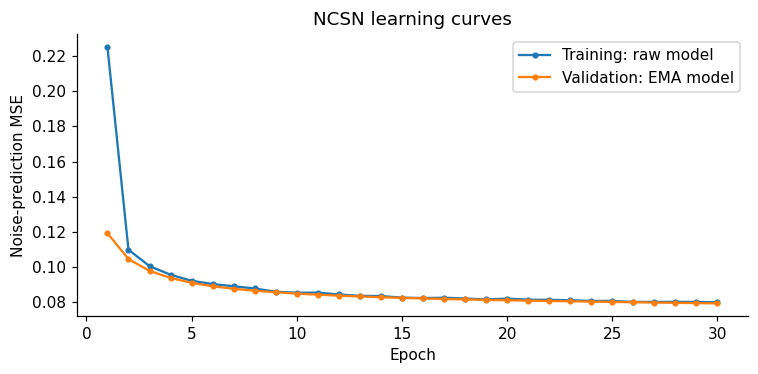

Held-out test noise MSE: 0.07817


In [13]:
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot(history_df['epoch'], history_df['train_mse'], marker='.', label='Training: raw model')
ax.plot(history_df['epoch'], history_df['val_mse'], marker='.',
        label='Validation: EMA model' if USE_EMA else 'Validation: raw model')
ax.set(xlabel='Epoch', ylabel='Noise-prediction MSE', title='NCSN learning curves')
ax.legend()
fig.tight_layout()
fig.savefig(RUN_DIR / 'learning_curves.png', dpi=160, bbox_inches='tight')
plt.show()
plt.close(fig)

test_mse = evaluate_noise_mse(sampling_model, test_loader, schedule, seed=2002)
test_summary = {'selected_update': selected_checkpoint['global_step'], 'test_noise_mse': test_mse,
                'test_weighted_dsm': 0.5 * IMAGE_SIZE**2 * test_mse, 'use_ema': USE_EMA,
                'test_size': len(test_data)}
(RUN_DIR / 'test_metrics.json').write_text(json.dumps(test_summary, indent=2))
print(f'Held-out test noise MSE: {test_mse:.5f}')


## 8. Annealed Langevin dynamics: uniform noise to new digits

Initialize $x\sim\mathrm{Unif}([0,1]^{784})$, following the paper's image experiments.
For $i=L,L-1,\ldots,1$, set
$$
\alpha_i=\eta\left(\frac{\sigma_i}{\sigma_1}\right)^2,
\qquad \eta=2\times10^{-5},
$$
then perform $K=100$ updates, using a **fresh** independent Gaussian draw each time:
$$
x\leftarrow x+\frac{\alpha_i}{2}s_\theta(x,\sigma_i)+\sqrt{\alpha_i}\epsilon
 =x-\frac{\alpha_i}{2\sigma_i}\epsilon_\theta(x,i)+\sqrt{\alpha_i}\epsilon,
\qquad\epsilon\sim\mathcal N(0,I_{784}).
$$
Keep the current image when changing levels. The step sizes decrease from 0.2 at $\sigma=1$
to $2\times10^{-5}$ at $\sigma=0.01$. There are ten score conditions and 1,000 total updates,
not 1,000 distinct diffusion times. Fresh Gaussian noise is added even on the final update.
The final stage targets $q_{\sigma_1}$, not the exactly clean distribution $q_0$.

**Paper versus released-code convention.** Algorithm 1 uses drift $\alpha s/2$ and noise
$\sqrt\alpha\epsilon$, and Section 5 reports base step $2\times10^{-5}$; these are our defaults.
The [released sampler](https://github.com/ermongroup/ncsn/blob/master/runners/anneal_runner.py)
instead uses drift $hs$ and noise $\sqrt{2h}\epsilon$ with base $h=2\times10^{-5}$.
Because $\alpha=2h$, set `BASE_ALPHA=4e-5` here to match that code's actual updates.
Changing this sampling setting does not require retraining.

No sampler state is clipped, and no extra final denoising step is added. Clipping is only for
display. `snapshot_every` controls stored frames, not how many updates are computed.


In [14]:
@torch.inference_mode()
def sample_ncsn(model, schedule, n_samples=8, seed=2026, steps_per_level=100,
                base_alpha=2e-5, snapshot_every=10, show_progress=True):
    if any(not isinstance(v, int) or v < 1 for v in (n_samples, steps_per_level, snapshot_every)):
        raise ValueError('Sample count, updates per level, and snapshot interval must be positive integers.')
    if not math.isfinite(base_alpha) or base_alpha <= 0:
        raise ValueError('base_alpha must be positive and finite.')
    model_device = next(model.parameters()).device
    if schedule.sigmas.device != model_device:
        raise ValueError('Move the model and noise schedule to the same device.')
    generator = torch.Generator(device='cpu').manual_seed(seed)
    shape = (n_samples, 1, 28, 28)
    x = torch.rand(shape, generator=generator).to(model_device)  # Uniform initialization.
    states, updates, levels = [x.cpu().clone()], [0], [0]       # level=0 here denotes initialization.
    stage_indices = [0]
    alphas = schedule.sampling_alphas(base_alpha)
    total_updates = schedule.levels * steps_per_level
    completed = 0
    was_training = model.training
    model.eval()
    progress = tqdm(total=total_updates, desc='Annealed Langevin generation', leave=False,
                    disable=not show_progress)
    try:
        for level_index in range(schedule.levels - 1, -1, -1):
            level = torch.full((n_samples,), level_index, device=model_device, dtype=torch.long)
            alpha = alphas[level_index]
            for within_level in range(1, steps_per_level + 1):
                score = predict_score(model, x, level, schedule)
                epsilon = torch.randn(shape, generator=generator).to(model_device)
                x = x + 0.5 * alpha * score + alpha.sqrt() * epsilon
                completed += 1
                if completed % snapshot_every == 0 or within_level == steps_per_level:
                    states.append(x.cpu().clone())         # Raw state, with no clipping.
                    updates.append(completed)
                    levels.append(level_index + 1)         # Mathematical label: 1,...,L.
                progress.update(1)
            if not torch.isfinite(x).all():
                raise FloatingPointError(f'Non-finite state at level {level_index+1}; inspect model/step size.')
            stage_indices.append(len(states) - 1)
        return {
            'samples': x.cpu().clone(), 'states': torch.stack(states), 'updates': updates,
            'levels': levels, 'stage_indices': stage_indices, 'seed': int(seed),
            'sigmas': schedule.sigmas.cpu().clone(), 'alphas': alphas.cpu().clone(),
            'steps_per_level': steps_per_level, 'base_alpha': float(base_alpha), 'nfe': completed,
        }
    finally:
        progress.close()
        model.train(was_training)


## 9. Generate and inspect every digit's trajectory

Each figure row follows one sample from initialization through the end of all ten stages.
The final column is exactly the returned sample. The GIF records every tenth Langevin update
by default (101 frames including initialization); reducing saved frames never skips computation.

The intensity scale is fixed at $[0,1]$ with clipping only in plots and exported images.
The compressed NumPy trajectory stores **unclipped** states, completed-update counts, levels,
sigmas, and step sizes. In trajectory metadata, level 0 marks initialization; it is not a
zero-noise stage. All later level labels are mathematical indices 1 through 10.


Annealed Langevin generation:   0%|          | 0/1000 [00:00<?, ?it/s]

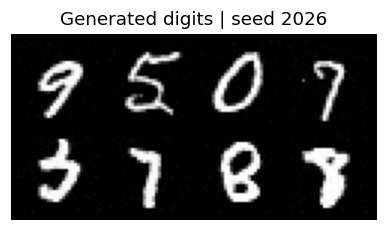

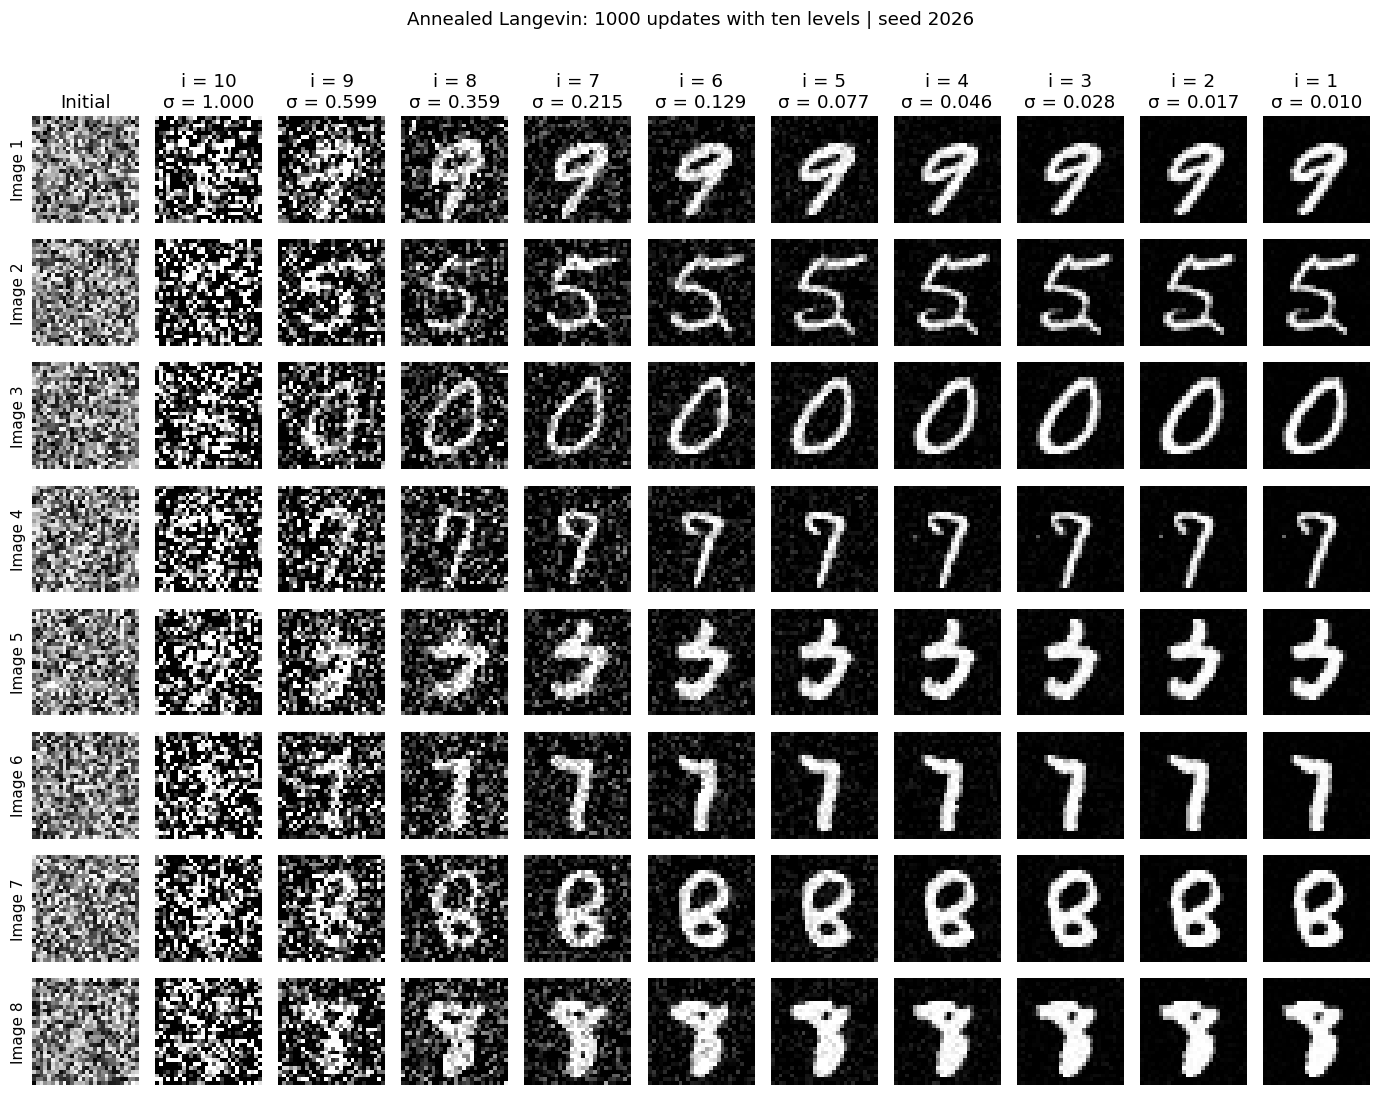

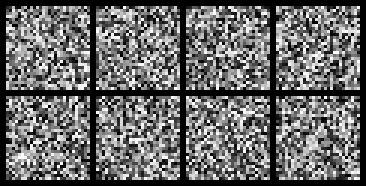

Saved generation: generation_seed2026_202618_276005 | U-Net evaluations: 1000


In [15]:
def save_trajectory_gif(result, path, nrow=4, scale=3):
    frames = []
    for state in result['states']:
        grid = make_grid(to_display(state), nrow=min(nrow, len(state)), padding=2, pad_value=0)
        array = (grid.permute(1, 2, 0).numpy() * 255).round().astype(np.uint8)
        frame = Image.fromarray(array)
        frame = frame.resize((frame.width * scale, frame.height * scale), resample=Image.Resampling.NEAREST)
        frames.append(frame)
    durations = [300] * len(frames)
    durations[-1] = 1200
    frames[0].save(path, save_all=True, append_images=frames[1:], duration=durations, loop=0)




def generate_digits(model, schedule, n_samples=8, seed=2026, save_gif=True,
                    steps_per_level=100, base_alpha=2e-5, snapshot_every=10, show_progress=True):
    result = sample_ncsn(model, schedule, n_samples=n_samples, seed=seed,
                         steps_per_level=steps_per_level, base_alpha=base_alpha,
                         snapshot_every=snapshot_every, show_progress=show_progress)
    tag = f'generation_seed{seed}_{datetime.now():%H%M%S_%f}'
    save_image(to_display(result['samples']), RUN_DIR / f'{tag}_digits.png',
               nrow=min(4, n_samples), padding=2, pad_value=0)
    np.savez_compressed(RUN_DIR / f'{tag}_trajectory.npz',
                        states=result['states'].numpy(), updates=np.array(result['updates']),
                        levels=np.array(result['levels']), stage_indices=np.array(result['stage_indices']),
                        sigmas=result['sigmas'].numpy(), alphas=result['alphas'].numpy(),
                        seed=seed, steps_per_level=steps_per_level, base_alpha=base_alpha, nfe=result['nfe'])
    show_digits(result['samples'], f'Generated digits | seed {seed}', nrow=min(4, n_samples))
    idx = result['stage_indices']
    labels = ['Initial'] + [f'i = {result["levels"][j]}\nσ = {result["sigmas"][result["levels"][j]-1]:.3f}'
                            for j in idx[1:]]
    show_trajectories(result['states'][idx], labels,
                      f'Annealed Langevin: 1000 updates with ten levels | seed {seed}'
                      if result['nfe'] == 1000 and schedule.levels == 10 else
                      f'Annealed Langevin: {result["nfe"]} updates | seed {seed}',
                      prefix=RUN_DIR / f'{tag}_trajectory')
    if save_gif:
        gif_path = RUN_DIR / f'{tag}.gif'
        save_trajectory_gif(result, gif_path)
        display(DisplayImage(filename=str(gif_path)))
    print(f'Saved generation: {tag} | U-Net evaluations: {result["nfe"]}')
    return result


if QUICK_RUN:
    print('Quick-run model: this checks execution, not final digit quality.')
generated = generate_digits(
    sampling_model, schedule, n_samples=NUM_GENERATED, seed=SAMPLE_SEED,
    save_gif=SAVE_GIF, steps_per_level=K, base_alpha=BASE_ALPHA,
    snapshot_every=SNAPSHOT_EVERY, show_progress=SHOW_PROGRESS,
)


In [16]:
# Generate a fresh batch with the SAME trained model and schedule:
# new_batch = generate_digits(sampling_model, schedule, n_samples=8, seed=2027,
#                             steps_per_level=K, base_alpha=BASE_ALPHA)
# To compare with the original code's actual step convention (without retraining):
# code_convention = generate_digits(sampling_model, schedule, seed=SAMPLE_SEED,
#                                   steps_per_level=K, base_alpha=4e-5)

print('Final samples:', tuple(generated['samples'].shape))
print('Saved trajectory:', tuple(generated['states'].shape))
print('Stage-end levels:', [generated['levels'][j] for j in generated['stage_indices'][1:]])
assert generated['nfe'] == L * K
assert generated['updates'][0] == 0 and generated['updates'][-1] == L * K
assert generated['levels'][-1] == 1
assert torch.equal(generated['samples'], generated['states'][-1])


Final samples: (8, 1, 28, 28)
Saved trajectory: (101, 8, 1, 28, 28)
Stage-end levels: [10, 9, 8, 7, 6, 5, 4, 3, 2, 1]


## 10. Reuse trained weights later

Set `LOAD_CHECKPOINT` in the settings cell and rerun to skip training. Alternatively, the helper
below reconstructs the network and schedule from checkpoint metadata, selecting raw or EMA
weights as saved. In a generation-only session, execute the imports, settings, and function/class
definitions from Sections 2–5 and 8–10, omitting their data/training/demo calls; then use the example.
MNIST itself is not needed to generate from saved weights.


In [17]:
def load_trained_ncsn(path, target_device=device):
    checkpoint = torch.load(Path(path), map_location='cpu', weights_only=True)
    config = checkpoint['config']
    if (config.get('architecture') != 'small_residual_unet_v1'
            or config.get('method') != 'ncsn_epsilon_v1' or config['image_size'] != 28):
        raise ValueError('Expected an NCSN 28×28 U-Net checkpoint from this notebook.')
    restored_model = SmallUNet(config['base_channels'], config['time_dim'], config['dropout'])
    weights = checkpoint['ema_state'] if config['use_ema'] else checkpoint['model_state']
    restored_model.load_state_dict(weights)
    restored_model = restored_model.to(target_device).eval().requires_grad_(False)
    restored_schedule = NoiseSchedule(config['L'], config['sigma_min'], config['sigma_max'],
                                       config['embedding_max']).to(target_device)
    return restored_model, restored_schedule, config


# Example (uncomment and replace the path):
# restored_model, restored_schedule, saved_config = load_trained_ncsn('outputs/.../best_ncsn.pt')
# restored_samples = generate_digits(restored_model, restored_schedule, n_samples=8, seed=2028,
#                                     steps_per_level=saved_config['K'],
#                                     base_alpha=saved_config['base_alpha'])


## Lab notes and useful experiments

- **Training versus sampling:** ten conditions are shared by one network. Each training image
  uses one randomly sampled condition. Each generated image uses all ten conditions, 100 times each.
- **Conditioning:** only the embedding coordinate is rescaled to $[1,1000]$. The image, sigma,
  number of levels, and number of optimizer updates are not rescaled by this mapping.
- **Score versus noise prediction:** the U-Net returns $\epsilon_\theta$; sampling always calls
  `predict_score`, which applies the essential minus sign and division by the current sigma.
- **No DDPM forward shrinkage:** corruption is $x+\sigma\epsilon$, not
  $\sqrt{\bar\alpha_t}x+\sqrt{1-\bar\alpha_t}\epsilon$. NCSN does not use DDPM's posterior mean.
- **What limits sample quality:** score errors, incomplete mixing, finite Langevin steps,
  residual smoothing at $\sigma_1$, and model capacity. Sharing DDPM's U-Net does not guarantee
  the same results. The supplied small U-Net and sinusoidal conditioning are intentional adaptations.
- **If samples are weak:** first check adequate training, the $[0,1]$ input scale, level ordering,
  and checkpoint compatibility. Then compare a few `base_alpha` values at fixed sampling seeds.
  Smaller steps may need more than 100 updates per level to explore comparably well.
- **Controlled comparison:** compare the paper's `base_alpha=2e-5` to the released code's
  equivalent `base_alpha=4e-5`, without changing trained weights or sampling seeds.
- **EMA experiment:** EMA is enabled by default to match the attached DDPM lab. Disable it
  before training to compare raw weights; original NCSN did not require EMA.
- **Reproducibility:** fixed local sampling seeds reproduce noise draws on the same setup;
  results can differ across devices and PyTorch versions.
- **Memory:** decrease batch size first. Reducing U-Net width changes the architecture and requires
  retraining. Saving every tenth update avoids storing all 1,000 full-batch states.

### References and implementation boundaries

- Song and Ermon (2019), [Generative Modeling by Estimating Gradients of the Data Distribution](https://papers.nips.cc/paper/2019/file/3001ef257407d5a371a96dcd947c7d93-Paper.pdf):
  weighted DSM (Section 4.2), annealed Langevin dynamics (Algorithm 1), and image settings (Section 5).
- Authors' [configuration](https://github.com/ermongroup/ncsn/blob/master/configs/anneal.yml),
  [loss](https://github.com/ermongroup/ncsn/blob/master/losses/dsm.py), and
  [runner/sampler](https://github.com/ermongroup/ncsn/blob/master/runners/anneal_runner.py):
  optimizer, dequantization, loss reduction, uniform initialization, and step-size convention.
- Ho, Jain, and Abbeel (2020), [Denoising Diffusion Probabilistic Models](https://arxiv.org/abs/2006.11239):
  context for the attached lab's U-Net and noise-prediction interface.

This is a teaching implementation of NCSN with the **attached network**, not the original
RefineNet/conditional-instance-normalization model. Epoch budget, shared optimizer settings,
gradient clipping, EMA, validation splitting, and trajectory plotting follow the attached DDPM lab.
The NCSN loss reduction remains unchanged. Sigmas, corruption, loss weighting,
the default annealed sampler, and their conventions are stated explicitly above.
